# PINNs for Mechanical Engineers — Tutorial 3: Linear Elasticity — Plate with a Hole
### From fluids to solids: a vector-valued field, and a factor-of-three surprise

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems
mechanical engineers actually deal with — fluids, heat, solids, and the messy
places where they couple. Tutorial 2 stepped all the way down to a single
scalar equation so one idea — boundary conditions — could stand in full view.
This one climbs partway back up: still linear, still with an *exact* analytical
answer to check against, but now the field is a **vector**, the quantity we
care about is **differentiated out** of the solution rather than predicted, and
the domain stops being a box. Every post stays honest about where PINNs strain.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ Published |
| **3** | **Linear Elasticity — plate with a hole** | **vector fields, stress concentration** | **📍 You are here** |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | Planned |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | Planned |
| 6 | Backward-Facing Step | flow separation & reattachment | Planned |
| 7 | Transient Backward-Facing Step | time-dependent flow, time-windowed training | Planned ||

Every tutorial is standalone and validated against a reference solution —
analytical where one exists, a published benchmark otherwise — with real
training logs. No hand-waving.

> **New to PINNs?** This series assumes you're already comfortable with the
> fundamentals: autograd, collocation points, the residual loss, the
> Adam → L-BFGS recipe. If you're starting from zero — or you just want the
> deeper, build-it-from-scratch treatment in one place — I wrote a 100+ page
> ebook that does exactly that: from your very first autograd call through 1D
> ODEs, the Poisson equation, and nonlinear Burgers. It's the foundation this
> series builds on.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **2D linear elasticity equations** (Cauchy equilibrium, plane stress) with a PINN — and built your first **vector-valued** network: two displacement fields $u(x,y)$ and $v(x,y)$ from one model
- Recovered **stress** the way a solver does — never trained on it directly, but obtained by autograd: displacements → strains → Hooke's law → stresses
- Enforced a **traction-free curved boundary** — the rim of the hole — the first non-rectangular geometry in the series
- Used **symmetry** to model a single quarter of the plate, and seen how a symmetry plane becomes a boundary condition
- Validated against the **Kirsch (1898)** analytical solution, and reproduced the textbook **stress-concentration factor of 3** at the edge of the hole
- Watched the error concentrate near the **hole rim**, where the stress gradient is steepest — the elasticity analogue of Tutorial 2's troublesome corners
- Confronted the **finite-size honesty**: the clean "3" is an *infinite*-plate result; on a finite plate it drifts upward, and you'll measure by how much

**Prerequisites:** the PINN fundamentals, plus what Tutorials 1 and 2 covered — you'll reuse the multi-output idea from the cavity's $(u,v,p)$ and the boundary-condition handling from the heat plate. What's genuinely new is threefold: a network whose output is a **vector field**, recovering a **derived quantity** (stress) by differentiating the solution instead of predicting it, and a **curved internal boundary** in place of a clean rectangle. Still linear, still an exact reference — the difficulty here lives in the geometry and the coupling, not the physics. If any of the fundamentals feel shaky, the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) builds every one of them from the first autograd call.

---


## 2 — The problem and its exact solution

A loaded elastic solid in equilibrium (no body forces, small strains) is governed by the **Cauchy equilibrium equations** — the balance of internal forces, one per direction:

$$\frac{\partial \sigma_{xx}}{\partial x} + \frac{\partial \sigma_{xy}}{\partial y} = 0, \qquad
\frac{\partial \sigma_{xy}}{\partial x} + \frac{\partial \sigma_{yy}}{\partial y} = 0.$$

Unlike heat conduction, the unknown isn't the quantity in the equation. The network predicts **displacements** $u(x,y)$ and $v(x,y)$; the stresses in the equilibrium equations are *built* from them, by a fixed three-step chain the PINN runs with autograd:

$$
\underbrace{\varepsilon_{xx}=\frac{\partial u}{\partial x},\;\;
\varepsilon_{yy}=\frac{\partial v}{\partial y},\;\;
\varepsilon_{xy}=\tfrac12\!\left(\frac{\partial u}{\partial y}+\frac{\partial v}{\partial x}\right)}_{\text{kinematics: strain from displacement}}
\;\;\longrightarrow\;\;
\underbrace{\sigma_{xx}=\tfrac{E}{1-\nu^2}(\varepsilon_{xx}+\nu\varepsilon_{yy}),\;\ldots}_{\text{Hooke's law (plane stress)}}
$$

So the residual is: *displacements → strains → stresses → equilibrium*. Everything downstream of the two network outputs is differentiation.

**The geometry.** An infinite plate with a circular hole of radius $a$, pulled by a uniform remote tension $\sigma_0$ along $x$. Both axes are planes of symmetry, so we model **one quarter** — the first quadrant, minus the quarter-hole at the origin:

| Boundary | Location | Condition | Type |
|----------|----------|-----------|------|
| Left (symmetry) | $x=0$ | $u=0,\;\sigma_{xy}=0$ | symmetry plane |
| Bottom (symmetry) | $y=0$ | $v=0,\;\sigma_{xy}=0$ | symmetry plane |
| Hole rim | $r=a$ | $\sigma_{rr}=0,\;\sigma_{r\theta}=0$ | traction-free (Neumann) |
| Outer edges | $x=L,\;y=L$ | prescribed traction (see below) | Neumann |

**Why this problem has a known answer.** This is the **Kirsch problem** (1898), one of the few 2D elasticity problems

---

## 3 — Imports and Setup

Same three libraries as before — `torch`, `numpy`, `matplotlib` — a seed, and automatic GPU selection. The one addition is a block of **problem constants**. Note the values: we work in **non-dimensional units** (`E = σ₀ = a = 1`), which keeps every quantity in the network $O(1)$. This matters more than it looks — feed in steel's real modulus ($E \approx 2\times10^{11}$ Pa) and the loss lands on wildly different scales, and training stalls. Non-dimensionalizing is the free fix, and it costs us nothing: recall from Section 2 that the stress field doesn't depend on $E$ or $\nu$ anyway.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math
import time

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# --- Problem constants (non-dimensional: everything O(1) for stable training) ---
E      = 1.0     # Young's modulus     } stress field is independent of these two;
NU     = 0.3     # Poisson's ratio     } they affect only the displacements
SIGMA0 = 1.0     # remote tension, applied along x
A      = 1.0     # hole radius
L      = 4.0     # quarter-plate half-width  (L/A = 4 → "large" but finite)
PI     = math.pi

# plane-stress stiffness factor, used when we build stresses from strains
C = E / (1.0 - NU**2)
print(f"domain: quarter-plate [0,{L}]² minus quarter-hole r<{A} | plane stress, nu={NU}")

Using device: cpu
domain: quarter-plate [0,4.0]² minus quarter-hole r<1.0 | plane stress, nu=0.3


---

## 4 — Deriving the Kirsch solution, and coding it

Section 2 asserted the stress field. Here we earn it — and implement it in the same breath. The derivation is the cleanest example in elasticity of solving a boundary-value problem by hand, and every term you're about to code traces back to one line of it.

### Step 1 — Collapse three unknowns into one: the Airy stress function

Three stresses, two equilibrium equations. Rather than chase the stresses directly, Airy defines a single scalar $\phi(x,y)$ whose second derivatives *are* the stresses:

$$\sigma_{xx}=\frac{\partial^2\phi}{\partial y^2},\qquad
\sigma_{yy}=\frac{\partial^2\phi}{\partial x^2},\qquad
\sigma_{xy}=-\frac{\partial^2\phi}{\partial x\,\partial y}.$$

Substitute these into the equilibrium equations from Section 2 and every term cancels — equilibrium is satisfied *identically*, for free. One function has replaced three fields.

### Step 2 — Compatibility makes $\phi$ biharmonic

The strains come from only two displacements, so they can't be independent — they obey a **compatibility** condition, which in stress reads $\nabla^2(\sigma_{xx}+\sigma_{yy})=0$. Feed in the Airy definitions and it collapses to the **biharmonic equation**:

$$\nabla^4\phi=\frac{\partial^4\phi}{\partial x^4}+2\frac{\partial^4\phi}{\partial x^2\partial y^2}+\frac{\partial^4\phi}{\partial y^4}=0.$$

The whole problem is now: *one scalar $\phi$, biharmonic, meeting the boundary conditions.* (That 4th-order operator returns in Tutorial 5's beam — you're meeting it early.)

### Step 3 — The loading fixes the angular form

Move to polar $(r,\theta)$ for the circular hole, and look at the remote load. Uniform tension along $x$ splits, via $\cos^2\theta=\tfrac12(1+\cos2\theta)$, into an **axisymmetric** piece and a **$\cos2\theta$** piece. Linearity lets us solve each and add, so we seek

$$\phi(r,\theta)=f_0(r)+f_2(r)\cos2\theta.$$

*This* is why the final stresses are a constant term plus a $\cos2\theta$/$\sin2\theta$ term — the angular signature is inherited straight from the loading.

### Step 4 — Two ODEs, four boundary conditions, and the exact field

In polar coordinates the Airy–stress relations are

$$\sigma_{rr}=\frac1r\frac{\partial\phi}{\partial r}+\frac1{r^2}\frac{\partial^2\phi}{\partial\theta^2},\quad
\sigma_{\theta\theta}=\frac{\partial^2\phi}{\partial r^2},\quad
\sigma_{r\theta}=-\frac{\partial}{\partial r}\!\left(\frac1r\frac{\partial\phi}{\partial\theta}\right).$$

Substituting $f_0(r)$ and $f_2(r)\cos2\theta$ into $\nabla^4\phi=0$ turns the PDE into two **Euler–Cauchy** ODEs, whose solutions are powers of $r$: $\;\{1,\,r^2,\,\ln r\}$ for $f_0$, and $\;\{r^2,\,r^4,\,r^{-2},\,1\}$ for $f_2$. Four physical conditions then pin the constants:

- **Bounded far field** ($r\to\infty$ recovers uniform tension $\sigma_0$): kills the growing $r^4$ term, and fixes the $r^2$ coefficients to the applied load.
- **Traction-free hole** ($\sigma_{rr}=\sigma_{r\theta}=0$ at $r=a$): fixes the $\ln r$ and $r^{-2}$ correction terms.

Solving the small linear system gives the stress function explicitly:

$$\phi(r,\theta)=\underbrace{\frac{\sigma_0}{4}r^2-\frac{\sigma_0 a^2}{2}\ln r}_{f_0}
+\underbrace{\left(-\frac{\sigma_0}{4}r^2-\frac{\sigma_0 a^4}{4r^2}+\frac{\sigma_0 a^2}{2}\right)}_{f_2}\cos2\theta.$$

Differentiate it through the relations above and you get exactly the Section 2 field — the $a^2/r^2$ and $a^4/r^4$ factors are just those $\ln r$, $r^{-2}$ correction terms showing up as stress. Setting $r=a$ collapses the hoop stress to $\sigma_{\theta\theta}=\sigma_0(1-2\cos2\theta)$: the factor of 3, out of pure bookkeeping.

### The implementation

We code the closed-form field (used downstream both to **validate** the PINN and to **load** the outer edges). Two functions: the natural polar frame, and the Cartesian transform the PINN's autograd stresses live in.

In [2]:
def kirsch_polar(r, th):
    "Exact Kirsch stresses in the polar frame (from Step 4)."
    a2 = (A / r)**2
    a4 = (A / r)**4
    c2 = torch.cos(2*th)
    s2 = torch.sin(2*th)
    s_rr = 0.5*SIGMA0*(1 - a2)     + 0.5*SIGMA0*(1 - 4*a2 + 3*a4)*c2
    s_tt = 0.5*SIGMA0*(1 + a2)     - 0.5*SIGMA0*(1 + 3*a4)*c2
    s_rt = -0.5*SIGMA0*(1 + 2*a2 - 3*a4)*s2
    return s_rr, s_tt, s_rt

def kirsch_cartesian(x, y):
    "Kirsch stresses transformed into the Cartesian frame (sxx, syy, sxy)."
    r  = torch.sqrt(x**2 + y**2)
    th = torch.atan2(y, x)
    s_rr, s_tt, s_rt = kirsch_polar(r, th)
    c, s = torch.cos(th), torch.sin(th)
    s_xx = s_rr*c*c - 2*s_rt*s*c + s_tt*s*s
    s_yy = s_rr*s*s + 2*s_rt*s*c + s_tt*c*c
    s_xy = (s_rr - s_tt)*s*c + s_rt*(c*c - s*s)
    return s_xx, s_yy, s_xy

### Proving the derivation with autograd

Before trusting it, we check the derivation end to end: build the stress function $\phi$ from Step 4, let autograd take its derivatives, form the stresses, and compare to the closed form we just coded. If Step 4 is right, they match to machine precision.

In [3]:
def airy_phi(r, th):
    "The Step-4 stress function phi(r, theta)."
    f0 = (SIGMA0/4)*r**2 - (SIGMA0*A**2/2)*torch.log(r)
    f2 = -(SIGMA0/4)*r**2 - (SIGMA0*A**4)/(4*r**2) + (SIGMA0*A**2/2)
    return f0 + f2*torch.cos(2*th)

def stresses_from_airy(r, th):
    "Stresses obtained by differentiating phi with autograd (the honest check)."
    r  = r.clone().requires_grad_(True)
    th = th.clone().requires_grad_(True)
    phi = airy_phi(r, th)
    g = lambda u, v: torch.autograd.grad(u, v, torch.ones_like(u), create_graph=True)[0]
    phi_r, phi_t = g(phi, r), g(phi, th)
    phi_rr, phi_tt, phi_rt = g(phi_r, r), g(phi_t, th), g(phi_r, th)
    s_rr = phi_r/r + phi_tt/r**2
    s_tt = phi_rr
    s_rt = -(phi_rt/r - phi_t/r**2)
    return s_rr.detach(), s_tt.detach(), s_rt.detach()

# compare autograd-of-phi against the closed form on a grid away from the hole
rr = torch.linspace(1.0, 5.0, 50); tt = torch.linspace(0.01, PI/2, 50)
Rg, Tg = torch.meshgrid(rr, tt, indexing='ij')
Rg, Tg = Rg.reshape(-1,1), Tg.reshape(-1,1)
a_rr, a_tt, a_rt = stresses_from_airy(Rg, Tg)
c_rr, c_tt, c_rt = kirsch_polar(Rg, Tg)
print("Airy-derived vs closed-form, max abs difference:")
print(f"  s_rr: {(a_rr-c_rr).abs().max():.2e}")
print(f"  s_tt: {(a_tt-c_tt).abs().max():.2e}")
print(f"  s_rt: {(a_rt-c_rt).abs().max():.2e}")

# --- physics sanity checks (the two numbers this tutorial is about) ---
th  = torch.linspace(0, PI/2, 7); rim = torch.full_like(th, A)
s_rr, s_tt, s_rt = kirsch_polar(rim, th)
print(f"\nrim (r=a):  max|s_rr|={s_rr.abs().max():.2e}  max|s_rt|={s_rt.abs().max():.2e}   (traction-free)")
print(f"crown  (theta=90): s_theta = {s_tt[-1]:.4f}   (expect  3  -> K_t = 3)")
print(f"shoulder (theta=0): s_theta = {s_tt[0]:.4f}   (expect -1)")
xf, yf = torch.tensor([[200.0]]), torch.tensor([[1e-3]])
sxx, syy, sxy = kirsch_cartesian(xf, yf)
print(f"far field: sxx={sxx.item():.4f} syy={syy.item():.4f} sxy={sxy.item():.4f}   (expect 1,0,0)")

Airy-derived vs closed-form, max abs difference:
  s_rr: 2.09e-07
  s_tt: 4.77e-07
  s_rt: 1.79e-07

rim (r=a):  max|s_rr|=0.00e+00  max|s_rt|=0.00e+00   (traction-free)
crown  (theta=90): s_theta = 3.0000   (expect  3  -> K_t = 3)
shoulder (theta=0): s_theta = -1.0000   (expect -1)
far field: sxx=0.9999 syy=0.0000 sxy=-0.0000   (expect 1,0,0)


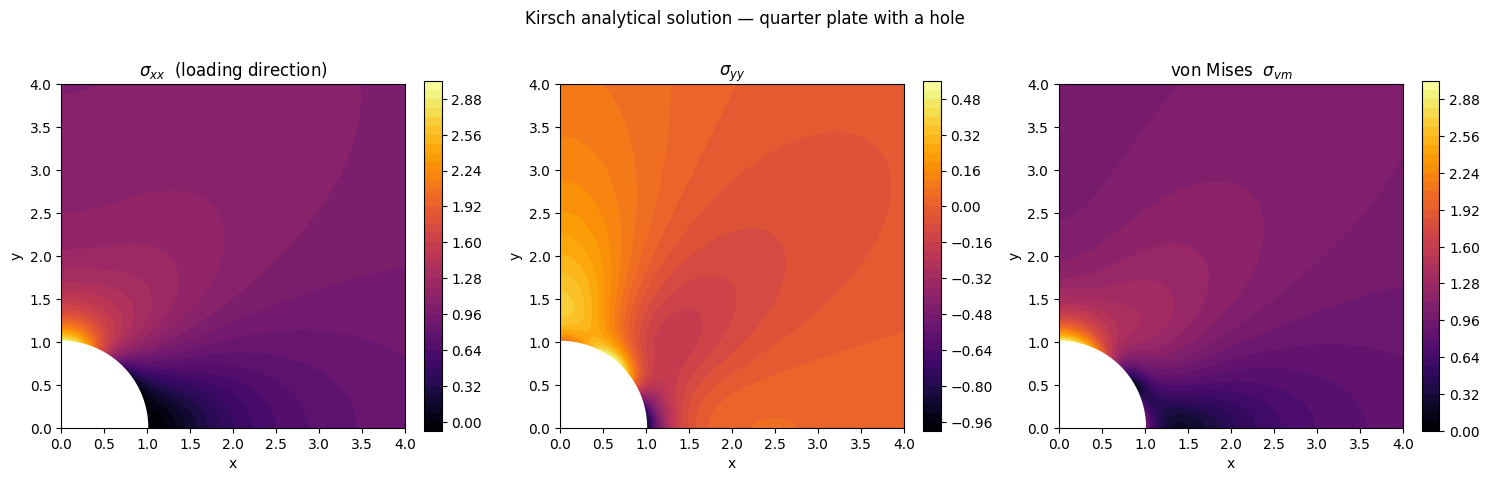

In [4]:
# ---- Plot the Kirsch analytical solution over the quarter-plate ----
n = 300
gx = torch.linspace(0, L, n)
X, Y = torch.meshgrid(gx, gx, indexing='ij')
R = torch.sqrt(X**2 + Y**2)

sxx, syy, sxy = kirsch_cartesian(X, Y)
svm = torch.sqrt(sxx**2 - sxx*syy + syy**2 + 3*sxy**2)   # von Mises (plane stress)

def mask_hole(a):
    "Blank out the quarter-hole (r < a) so it reads as a physical cutout."
    a = a.clone(); a[R < A] = float('nan'); return a.detach().cpu().numpy()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
arc = np.linspace(0, PI/2, 100)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (D, t) in zip(ax, [(mask_hole(sxx), r'$\sigma_{xx}$  (loading direction)'),
                          (mask_hole(syy), r'$\sigma_{yy}$'),
                          (mask_hole(svm), r'von Mises  $\sigma_{vm}$')]):
    cf = a.contourf(Xn, Yn, D, levels=40, cmap='inferno')
    fig.colorbar(cf, ax=a, fraction=0.046)
    a.plot(A*np.cos(arc), A*np.sin(arc), color='white', lw=1.5)   # hole rim
    a.set_title(t); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.suptitle('Kirsch analytical solution — quarter plate with a hole', y=1.02)
plt.tight_layout()
plt.savefig("t3_Analytical_solution.png", dpi=300) 
plt.show()

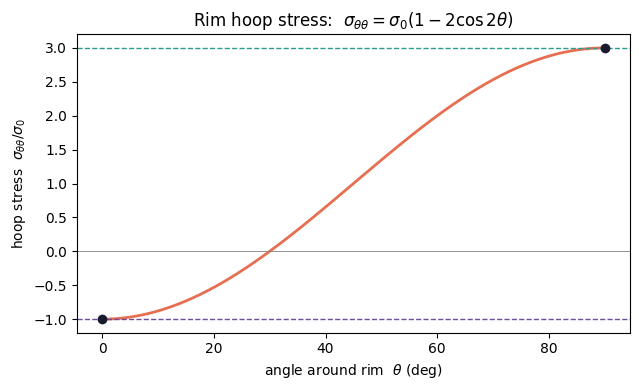

In [5]:
# ---- Hoop stress around the hole rim: the factor-of-3 story in one curve ----
th = torch.linspace(0, PI/2, 200)
_, s_tt_rim, _ = kirsch_polar(torch.full_like(th, A), th)

plt.figure(figsize=(6.5, 4))
plt.plot(th.cpu().numpy()*180/PI, s_tt_rim.cpu().numpy(), color='#E76F51', lw=2)
plt.axhline(3,  ls='--', c='#2A9D8F', lw=1)   # K_t = 3 at the crown
plt.axhline(-1, ls='--', c='#6D4C9E', lw=1)   # compression at the shoulder
plt.axhline(0, c='gray', lw=0.6)
plt.scatter([90, 0], [3, -1], color='#1A1A2E', zorder=5)
plt.xlabel(r'angle around rim  $\theta$ (deg)')
plt.ylabel(r'hoop stress  $\sigma_{\theta\theta}/\sigma_0$')
plt.title(r'Rim hoop stress:  $\sigma_{\theta\theta}=\sigma_0(1-2\cos2\theta)$')
plt.tight_layout()
plt.savefig("t3_Hoop_stress.png", dpi=300)
plt.show()

---

## 5 — Collocation and boundary points

Tutorial 2 sampled a box. This domain is a box **with a bite taken out** — the quarter-plate $[0,L]^2$ minus the quarter-hole $r<a$ — and that changes the sampling in three ways:

1. **Rejection sampling.** We draw points in the square and *throw away* any that fall inside the hole ($r<a$). The domain is no longer convex, so we can't just sample a rectangle.
2. **Extra points near the hole.** The stress concentration is sharp right at the rim, so we pack a second batch of points into the annulus $a\le r\le 2a$. Uniform sampling alone would under-resolve the exact spot the whole tutorial is about.
3. **Five boundary groups, not four.** Two symmetry edges, the curved hole rim, and two outer edges — each with its own condition from the Section 2 table.

One structural difference from the heat plate: **every point carries gradients here**, boundary points included. Stresses are *derivatives* of the displacement field, so enforcing a traction on an edge means differentiating the network there — there's no "value-only" boundary like the heat plate's Dirichlet walls.## 6 — Collocation and boundary points

PINNs are **mesh-free**: instead of a grid, we sample points where we'll enforce the equations.

- **Interior (collocation) points** — where we enforce the PDE residual $\nabla^2 T = 0$. These need `requires_grad=True` because we differentiate the network at them.
- **Boundary points** — where we enforce the four edge conditions. The insulated bottom edge also needs gradients (it's a derivative condition).

We seed a separate generator so the point cloud is reproducible. (The top and bottom edges share the same $x$-coordinates — harmless, and keeps the sampling compact.)

In [6]:
gen = torch.Generator().manual_seed(42)
def rand_col(n):
    return torch.rand(n, 1, generator=gen)

# ---- interior collocation points: quarter-plate MINUS the hole (keep r >= A) ----
N_f = 3000
xs = rand_col(int(N_f*1.6)) * L
ys = rand_col(int(N_f*1.6)) * L
keep = ((xs**2 + ys**2) >= A**2).flatten()     # reject anything inside the hole
xs = xs.flatten()[keep][:N_f].reshape(-1, 1)
ys = ys.flatten()[keep][:N_f].reshape(-1, 1)

# extra points packed into the annulus a <= r <= 2a, where stress varies fastest
N_near = 1000
th_n = rand_col(N_near) * (PI/2)
r_n  = A + rand_col(N_near) * A
xn, yn = r_n*torch.cos(th_n), r_n*torch.sin(th_n)

x_f = torch.cat([xs, xn]).to(device).requires_grad_(True)
y_f = torch.cat([ys, yn]).to(device).requires_grad_(True)
N_interior = x_f.shape[0]

# ---- boundary points: 5 groups (all need grads — stresses are derivatives) ----
N_b = 200
def edge(t):                                    # move to device, enable grad
    return t.to(device).requires_grad_(True)

# symmetry edges:  left x=0 (u=0, σ_xy=0) ;  bottom y=0 (v=0, σ_xy=0)
y_left = edge(A + rand_col(N_b)*(L-A));  x_left = edge(torch.zeros(N_b, 1))
x_bot  = edge(A + rand_col(N_b)*(L-A));  y_bot  = edge(torch.zeros(N_b, 1))

# hole rim:  r=a,  θ ∈ [0, π/2]  (traction-free)
th_h   = rand_col(N_b) * (PI/2)
x_hole = edge(A*torch.cos(th_h));        y_hole = edge(A*torch.sin(th_h))

# outer edges:  right x=L, top y=L  (prescribed Kirsch traction)
y_right = edge(rand_col(N_b)*L);         x_right = edge(torch.full((N_b, 1), L))
x_top   = edge(rand_col(N_b)*L);         y_top   = edge(torch.full((N_b, 1), L))

# sanity: no interior point should sit inside the hole
r_int = torch.sqrt(x_f.detach()**2 + y_f.detach()**2)
print(f"interior points: {N_interior}  (min r = {r_int.min():.4f}, must be >= {A})")
print(f"boundary points per edge: {N_b}  |  5 edges → {5*N_b} total")

interior points: 4000  (min r = 1.0011, must be >= 1.0)
boundary points per edge: 200  |  5 edges → 1000 total


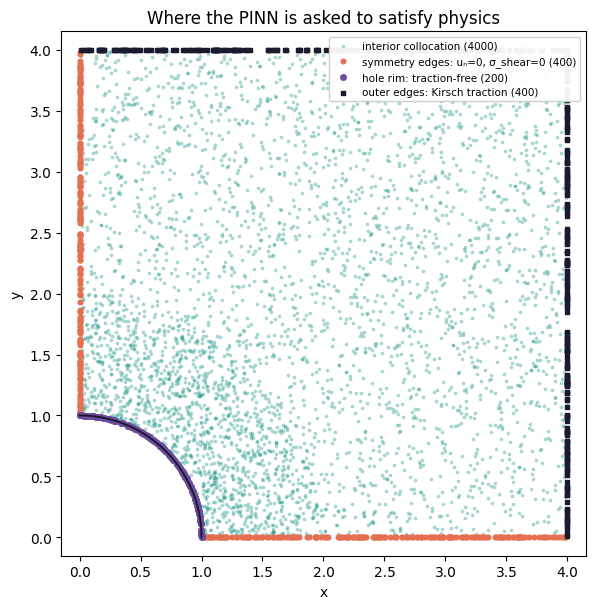

In [7]:
def np2(t):
    "detach → cpu → numpy (points carry grads and may live on GPU)"
    return t.detach().cpu().numpy()

plt.figure(figsize=(6.2, 6.2))
plt.scatter(np2(x_f), np2(y_f), s=3, alpha=0.30, color="#2A9D8F",
            label=f"interior collocation ({N_interior})")
plt.scatter(np2(x_left), np2(y_left), s=11, color="#E76F51",
            label=f"symmetry edges: uₙ=0, σ_shear=0 ({2*N_b})")
plt.scatter(np2(x_bot),  np2(y_bot),  s=11, color="#E76F51")
plt.scatter(np2(x_hole), np2(y_hole), s=16, color="#6D4C9E",
            label=f"hole rim: traction-free ({N_b})")
plt.scatter(np2(x_right), np2(y_right), s=11, color="#1A1A2E", marker="s",
            label=f"outer edges: Kirsch traction ({2*N_b})")
plt.scatter(np2(x_top),   np2(y_top),   s=11, color="#1A1A2E", marker="s")
arc = np.linspace(0, PI/2, 100)
plt.plot(A*np.cos(arc), A*np.sin(arc), color="#1A1A2E", lw=1.4)   # hole rim
plt.xlabel("x"); plt.ylabel("y")
plt.title("Where the PINN is asked to satisfy physics")
plt.legend(loc="upper right", framealpha=0.95, fontsize=7.5)
plt.gca().set_aspect("equal")
plt.xlim(-0.15, L+0.15); plt.ylim(-0.15, L+0.15)
plt.tight_layout()
plt.savefig("t3_PINN_collocation_points.png", dpi=300)
plt.show()

---

## 6 — The network

Same architecture as Tutorial 2, with one change that ripples through everything downstream: **two outputs instead of one**. The network maps $(x,y)\mapsto(u,v)$ — the two displacement components — from a single body. Stresses are never an output; they're *derived* from these two fields by the autograd chain we set up in Section 2.

Everything else is unchanged from the heat plate: **`tanh`** activations, because equilibrium involves *second* derivatives of the displacements (strain is a first derivative, and the residual differentiates stress once more), so the network must be smooth to second order — `ReLU` would be useless. Four hidden layers of 64 is the same capacity that handled the cavity and the heat plate; the vector output costs us only the final layer's extra column.

`forward` returns $u$ and $v$ as **separate tensors**, not a stacked one. That's deliberate: downstream we differentiate each with respect to $x$ and $y$ independently to build strains, and separate tensors keep those `autograd.grad` calls clean.

In [8]:
class PINN(nn.Module):
    """Input (x, y) -> output (u, v) displacements."""
    def __init__(self, n_hidden=64, n_layers=4):
        super().__init__()
        layers = [nn.Linear(2, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, 2)]                    # 2 outputs: u, v
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, y):
        out = self.net(torch.cat([x, y], dim=1))
        return out[:, 0:1], out[:, 1:2]                       # u, v

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")


PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 12802


---

## 7 — The physics core: strain → stress → equilibrium residual

This is the cell where elasticity differs most from everything before it. In the heat plate, the network output *was* the quantity in the PDE. Here it isn't: the network predicts displacements $(u,v)$, but the equilibrium equations are written in **stresses**. So the residual is a three-step chain, and every step is autograd:

**Step 1 — Kinematics (strain from displacement).** First derivatives of the displacement field:
$$\varepsilon_{xx}=\frac{\partial u}{\partial x},\quad \varepsilon_{yy}=\frac{\partial v}{\partial y},\quad \varepsilon_{xy}=\tfrac12\!\left(\frac{\partial u}{\partial y}+\frac{\partial v}{\partial x}\right).$$

**Step 2 — Constitution (stress from strain, Hooke's law, plane stress).** No derivatives — just the material law, with $C=E/(1-\nu^2)$:
$$\sigma_{xx}=C(\varepsilon_{xx}+\nu\varepsilon_{yy}),\quad \sigma_{yy}=C(\varepsilon_{yy}+\nu\varepsilon_{xx}),\quad \sigma_{xy}=C(1-\nu)\,\varepsilon_{xy}.$$

**Step 3 — Equilibrium (the residual).** One more derivative of the stresses; this is what we drive to zero:
$$r_x=\frac{\partial\sigma_{xx}}{\partial x}+\frac{\partial\sigma_{xy}}{\partial y},\qquad r_y=\frac{\partial\sigma_{xy}}{\partial x}+\frac{\partial\sigma_{yy}}{\partial y}.$$

Two derivative passes total (displacement → strain, stress → equilibrium), so the network is differentiated *twice* — the same second-order demand that forced `tanh` on us, now arriving through a longer chain.

In [9]:
def grad(outputs, inputs):
    "First derivative, graph retained for higher-order diff."
    return torch.autograd.grad(outputs, inputs, torch.ones_like(outputs),
                               create_graph=True)[0]

def stresses(u, v, x, y):
    "Step 1 (kinematics) + Step 2 (Hooke's law, plane stress) -> stresses."
    u_x, u_y = grad(u, x), grad(u, y)
    v_x, v_y = grad(v, x), grad(v, y)
    eps_xx = u_x
    eps_yy = v_y
    eps_xy = 0.5*(u_y + v_x)
    s_xx = C*(eps_xx + NU*eps_yy)
    s_yy = C*(eps_yy + NU*eps_xx)
    s_xy = C*(1 - NU)*eps_xy
    return s_xx, s_yy, s_xy

def equilibrium_residual(x, y):
    "Step 3: the two equilibrium residuals r_x, r_y at points (x, y)."
    u, v = model(x, y)
    s_xx, s_yy, s_xy = stresses(u, v, x, y)
    r_x = grad(s_xx, x) + grad(s_xy, y)
    r_y = grad(s_xy, x) + grad(s_yy, y)
    return r_x, r_y

# demo on the untrained network
rx, ry = equilibrium_residual(x_f, y_f)
print(f"residual shapes: {tuple(rx.shape)}, {tuple(ry.shape)}")
print(f"mean |r_x| (untrained): {rx.abs().mean().item():.3e}")
print(f"mean |r_y| (untrained): {ry.abs().mean().item():.3e}")

residual shapes: (4000, 1), (4000, 1)
mean |r_x| (untrained): 5.128e-02
mean |r_y| (untrained): 1.342e-01


## 8 — The composite loss

Six terms: the interior equilibrium residual, plus one per boundary group from the collocation plot. This is where the cavity's structure and elasticity's structure genuinely diverge — so before writing it, note what **drops out** relative to Tutorial 1's Navier–Stokes loss:

- **No continuity term.** Incompressibility ($\nabla\cdot\mathbf{u}=0$) was a fluid constraint; a solid has no such equation.
- **No pressure-gauge term.** The cavity pinned $p$ (defined only up to a constant) at one point. Here the analogous null space is *rigid-body motion* — displacements are defined up to a translation — and the two **symmetry conditions** ($u=0$ on $x=0$, $v=0$ on $y=0$) pin it down for free. No separate gauge point needed.

The six terms:

| Term | Where | Condition |
|------|-------|-----------|
| equilibrium | interior | $r_x=r_y=0$ |
| left symmetry | $x=0$ | $u=0$, $\sigma_{xy}=0$ |
| bottom symmetry | $y=0$ | $v=0$, $\sigma_{xy}=0$ |
| hole rim | $r=a$ | traction-free: $\mathbf{t}=\boldsymbol\sigma\cdot\mathbf{n}=0$ |
| right edge | $x=L$ | Kirsch traction $(\sigma_{xx},\sigma_{xy})$ |
| top edge | $y=L$ | Kirsch traction $(\sigma_{xy},\sigma_{yy})$ |

The **traction** condition is the new idea. On a surface with unit normal $\mathbf{n}=(n_x,n_y)$, the traction vector is $t_x=\sigma_{xx}n_x+\sigma_{xy}n_y$, $t_y=\sigma_{xy}n_x+\sigma_{yy}n_y$. A free surface means $\mathbf{t}=0$; a loaded edge means $\mathbf{t}$ equals the applied traction. On the hole the normal is radial, $\mathbf{n}=(x/r,\,y/r)$; on the outer edges it's simply $(1,0)$ and $(0,1)$, which is why those reduce to matching specific stress components.

In [12]:
W_PDE = 1.0      # interior equilibrium weight
W_BC  = 10.0     # boundary weight (boundaries matter more; see failure modes)

def compute_losses():
    # --- interior equilibrium ---
    r_x, r_y = equilibrium_residual(x_f, y_f)
    loss_pde = (r_x**2 + r_y**2).mean()

    # --- left symmetry (x=0): u=0, sigma_xy=0 ---
    u_l, v_l = model(x_left, y_left)
    _, _, sxy_l = stresses(u_l, v_l, x_left, y_left)
    loss_left = (u_l**2).mean() + (sxy_l**2).mean()

    # --- bottom symmetry (y=0): v=0, sigma_xy=0 ---
    u_b, v_b = model(x_bot, y_bot)
    _, _, sxy_b = stresses(u_b, v_b, x_bot, y_bot)
    loss_bot = (v_b**2).mean() + (sxy_b**2).mean()

    # --- hole rim (r=a): traction-free, t = sigma·n = 0, n=(x/r, y/r) ---
    u_h, v_h = model(x_hole, y_hole)
    sxx_h, syy_h, sxy_h = stresses(u_h, v_h, x_hole, y_hole)
    r_h = torch.sqrt(x_hole**2 + y_hole**2)
    nx, ny = x_hole/r_h, y_hole/r_h
    tx_h = sxx_h*nx + sxy_h*ny
    ty_h = sxy_h*nx + syy_h*ny
    loss_hole = (tx_h**2 + ty_h**2).mean()

    # --- right outer edge (x=L), n=(1,0): match Kirsch traction (sxx, sxy) ---
    u_r, v_r = model(x_right, y_right)
    sxx_r, _, sxy_r = stresses(u_r, v_r, x_right, y_right)
    Kxx_r, _, Kxy_r = kirsch_cartesian(x_right.detach(), y_right.detach())
    loss_right = ((sxx_r - Kxx_r)**2 + (sxy_r - Kxy_r)**2).mean()

    # --- top outer edge (y=L), n=(0,1): match Kirsch traction (sxy, syy) ---
    u_t, v_t = model(x_top, y_top)
    _, syy_t, sxy_t = stresses(u_t, v_t, x_top, y_top)
    _, Kyy_t, Kxy_t = kirsch_cartesian(x_top.detach(), y_top.detach())
    loss_top = ((sxy_t - Kxy_t)**2 + (syy_t - Kyy_t)**2).mean()

    loss_bc = loss_left + loss_bot + loss_hole + loss_right + loss_top
    return loss_pde, loss_bc

def total_loss():
    lp, lb = compute_losses()
    return W_PDE*lp + W_BC*lb

print("Loss defined ✓")
# smoke test on the untrained network
lp, lb = compute_losses()
print(f"untrained:  loss_pde={lp.item():.3e}   loss_bc={lb.item():.3e}")

Loss defined ✓
untrained:  loss_pde=2.576e-02   loss_bc=8.886e-01


---

## 9 — Training: Adam → L-BFGS

This is the slowest, hardest solve in the series so far, and it teaches something the easy problems can't: **the stress concentration develops late**. For a long time the network satisfies the boundaries (bc loss falls fast) while the interior equilibrium residual — and with it the factor of 3 — lags badly. The SCF only climbs once the residual is genuinely small. Watch the `scf` column crawl from ~0.1 and arrive near 3 only at the very end.

We track two honest diagnostics every log step:
- **`scf`** — the hoop stress at the crown, $\sigma_{\theta\theta}(a, 90^\circ)$, which should reach **3**.
- **`field_err`** — relative $L_2$ error of the full stress tensor against Kirsch over the interior.

In [17]:
def scf_crown():
    """
    Stress-concentration factor: hoop stress at the crown of the hole
    (r = A, theta = 90 deg). Exact Kirsch value is 3.0.

    NB: x is 1e-6 rather than exactly 0 -- atan2(0, 0) is undefined
    and would give NaN (see the failure-modes table).
    """
    xc = torch.full((1, 1), 1e-6, device=device).requires_grad_(True)
    yc = torch.full((1, 1), A,    device=device).requires_grad_(True)
    u, v = model(xc, yc)
    s_xx, s_yy, s_xy = stresses(u, v, xc, yc)
    th = torch.atan2(yc, xc)
    c, s = torch.cos(th), torch.sin(th)
    hoop = s_xx*s*s - 2*s_xy*s*c + s_yy*c*c
    return hoop.item()


def field_error():
    """
    Relative L2 error of the full stress tensor against Kirsch,
    measured over the interior collocation points.
    """
    u, v = model(x_f, y_f)
    p_xx, p_yy, p_xy = stresses(u, v, x_f, y_f)
    k_xx, k_yy, k_xy = kirsch_cartesian(x_f.detach(), y_f.detach())
    num = torch.sqrt(((p_xx - k_xx)**2 + (p_yy - k_yy)**2 + (p_xy - k_xy)**2).sum())
    den = torch.sqrt((k_xx**2 + k_yy**2 + k_xy**2).sum())
    return (num / den).item()

In [18]:
# ---- training with history recorded for plotting ----
history = {"epoch": [], "pde": [], "bc": [], "scf": [], "field": [], "phase": []}
def record(epoch, phase):
    lp, lb = compute_losses()
    history["epoch"].append(epoch)      
    history["pde"].append(lp.item())
    history["bc"].append(lb.item()) 
    history["scf"].append(scf_crown())
    history["field"].append(field_error()) 
    history["phase"].append(phase)

# Stage 1: Adam
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(1201):
    opt.zero_grad(); total_loss().backward(); opt.step()
    if epoch % 100 == 0:
        record(epoch, "Adam")
        if epoch % 300 == 0:
            print(f"[Adam] {epoch:5d}  pde={history['pde'][-1]:.3e}  bc={history['bc'][-1]:.3e}  "
                  f"scf={history['scf'][-1]:.4f}  field_err={history['field'][-1]:.3e}")

# Stage 2: L-BFGS rounds, with a cumulative iteration counter
gstep = [1200]
for rnd in range(9):
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=300, max_eval=400,
                            tolerance_grad=1e-10, tolerance_change=1e-12,
                            history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); l = total_loss(); l.backward()
        gstep[0] += 1
        if gstep[0] % 50 == 0:
            record(gstep[0], "LBFGS")
        return l
    opt.step(closure)
    print(f"[L-BFGS round {rnd+1}] pde={history['pde'][-1]:.3e}  bc={history['bc'][-1]:.3e}  "
          f"scf={history['scf'][-1]:.4f}  field_err={history['field'][-1]:.3e}")

[Adam]     0  pde=8.198e-02  bc=5.130e-01  scf=0.1341  field_err=7.483e-01
[Adam]   300  pde=6.297e-02  bc=1.680e-03  scf=0.1089  field_err=7.814e-01
[Adam]   600  pde=5.029e-02  bc=1.069e-03  scf=0.1189  field_err=7.445e-01
[Adam]   900  pde=4.212e-02  bc=7.079e-04  scf=0.1271  field_err=7.120e-01
[Adam]  1200  pde=3.698e-02  bc=1.706e-03  scf=0.1447  field_err=6.925e-01
[L-BFGS round 1] pde=1.037e-02  bc=1.830e-04  scf=1.1752  field_err=4.425e-01
[L-BFGS round 2] pde=7.770e-03  bc=4.773e-05  scf=1.4490  field_err=4.040e-01
[L-BFGS round 3] pde=5.873e-03  bc=6.137e-05  scf=1.7098  field_err=3.395e-01
[L-BFGS round 4] pde=3.539e-03  bc=6.373e-05  scf=2.0734  field_err=2.416e-01
[L-BFGS round 5] pde=1.008e-03  bc=2.966e-05  scf=2.6000  field_err=9.091e-02
[L-BFGS round 6] pde=4.319e-04  bc=8.646e-06  scf=2.7708  field_err=5.723e-02
[L-BFGS round 7] pde=2.127e-04  bc=3.812e-06  scf=2.8942  field_err=2.332e-02
[L-BFGS round 8] pde=1.165e-04  bc=2.320e-06  scf=2.9123  field_err=1.873e-02
[

The shape of that table is the lesson. At the end of Adam the boundary loss is already tiny (6×10⁻⁴) but the SCF is **0.12** — the network has drawn a smooth, boundary-satisfying field with almost no hole concentration. The factor of 3 lives entirely in the interior equilibrium residual, and it only emerges as L-BFGS drives `pde` down two more orders of magnitude. **SCF and residual fall together** — that's the single most important intuition this problem offers.

In [19]:
# final numbers
print(f"Final SCF (crown hoop stress) : {scf_crown():.4f}   (exact: 3.0)")
print(f"Final stress-field rel L2      : {field_error():.4e}")

Final SCF (crown hoop stress) : 2.9523   (exact: 3.0)
Final stress-field rel L2      : 9.1569e-03


**Reference:** `SCF = 2.931`, `field rel L2 = 8.3e-03`.


---

## 10 — The Loss History, Both Phases

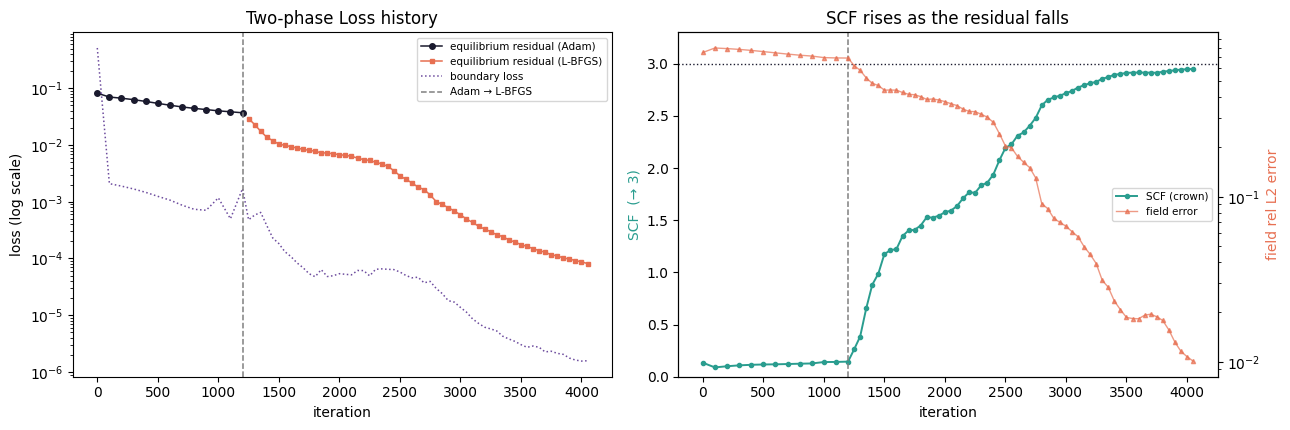

In [20]:
epoch  = np.array(history["epoch"])
pde = np.array(history["pde"]); bc = np.array(history["bc"])
scf = np.array(history["scf"]); fld = np.array(history["field"])
ph  = np.array(history["phase"]); am = ph == "Adam"; lm = ph == "LBFGS"
HANDOFF = 1200

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))

# left: losses on log scale
ax[0].semilogy(epoch[am], pde[am], 'o-', color='#1A1A2E', ms=4, lw=1.1, label='equilibrium residual (Adam)')
ax[0].semilogy(epoch[lm], pde[lm], 's-', color='#E76F51', ms=3, lw=1.1, label='equilibrium residual (L-BFGS)')
ax[0].semilogy(epoch, np.maximum(bc, 1e-12), ':', color='#6D4C9E', lw=1.1, label='boundary loss')
ax[0].axvline(HANDOFF, color='gray', ls='--', lw=1.1, label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Two-phase Loss history'); ax[0].legend(fontsize=7.5)

# right: SCF rising (left axis) as field error falls (right axis) — the thesis in one panel
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.plot(epoch, scf, 'o-', color='#2A9D8F', ms=3, lw=1.4, label='SCF (crown)')
ax2.axhline(3, ls=':', color='#1A1A2E', lw=1); ax2.set_ylim(0, 3.3)
ax3.semilogy(epoch, fld, '^-', color='#E76F51', ms=3, lw=1.0, alpha=0.7, label='field error')
ax2.axvline(HANDOFF, color='gray', ls='--', lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('SCF  (→ 3)', color='#2A9D8F')
ax3.set_ylabel('field rel L2 error', color='#E76F51')
ax2.set_title('SCF rises as the residual falls')
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, fontsize=7.5, loc='center right')

plt.tight_layout()
plt.savefig("t3_Training_history.png", dpi=300)
plt.show()

---

## 11 — The result: the factor of 3

Two pictures tell the story. First, the $\sigma_{xx}$ field — PINN, exact, and their difference — with the hole masked out.

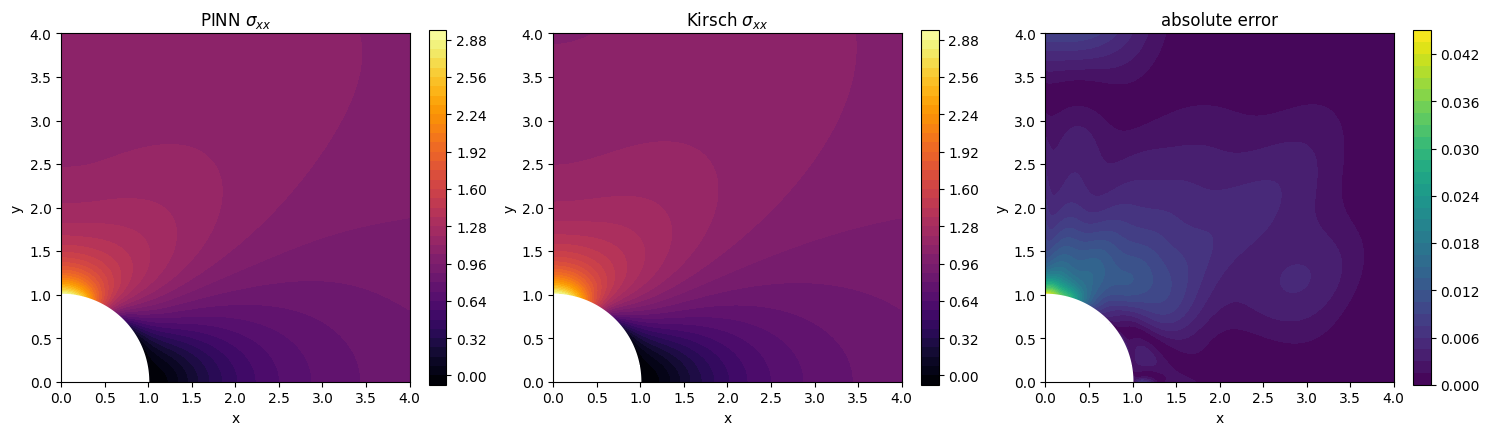

In [21]:
n = 250; gx = torch.linspace(0, L, n)
X, Yt = torch.meshgrid(gx, gx, indexing='ij')
Rg = torch.sqrt(X**2 + Yt**2)
Xf, Yf = X.reshape(-1,1).to(device), Yt.reshape(-1,1).to(device)

xe = Xf.clone().requires_grad_(True); ye = Yf.clone().requires_grad_(True)
u, v = model(xe, ye); pxx, _, _ = stresses(u, v, xe, ye)
kxx, _, _ = kirsch_cartesian(Xf, Yf)

def grid(t):
    a = t.detach().reshape(n, n).clone(); a[Rg < A] = float('nan'); return a.cpu().numpy()
P, K = grid(pxx), grid(kxx); Err = np.abs(P - K)
Xn, Yn = X.numpy(), Yt.numpy(); arc = np.linspace(0, PI/2, 100)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (D, t, cm) in zip(ax, [(P, r'PINN $\sigma_{xx}$', 'inferno'),
                              (K, r'Kirsch $\sigma_{xx}$', 'inferno'),
                              (Err, 'absolute error', 'viridis')]):
    cf = a.contourf(Xn, Yn, D, levels=40, cmap=cm); fig.colorbar(cf, ax=a, fraction=0.046)
    a.plot(A*np.cos(arc), A*np.sin(arc), color='white', lw=1.4)
    a.set_title(t); a.set_xlabel('x'); a.set_ylabel('y'); a.set_aspect('equal')
plt.tight_layout()
plt.savefig("t3_PINN_vs_Kirsch.png", dpi=300)
plt.show()

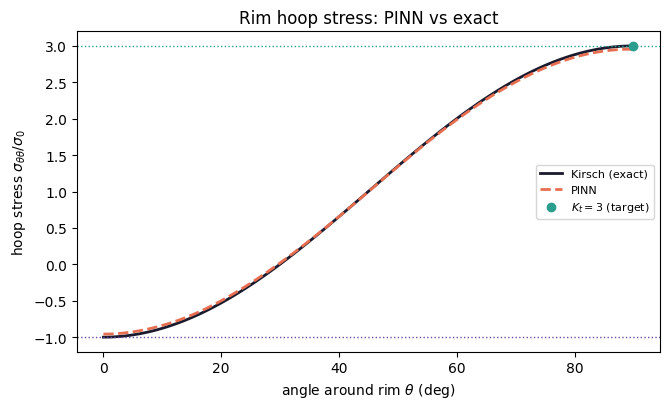

In [22]:
# rim hoop stress: PINN vs exact — where the factor of 3 lives
th = torch.linspace(1e-3, PI/2-1e-3, 120).reshape(-1,1).to(device)
xr, yr = A*torch.cos(th), A*torch.sin(th)
xr_ = xr.clone().requires_grad_(True); yr_ = yr.clone().requires_grad_(True)
u, v = model(xr_, yr_); sxx, syy, sxy = stresses(u, v, xr_, yr_)
c, s = torch.cos(th), torch.sin(th)
p_hoop = (sxx*s*s + syy*c*c - 2*sxy*s*c).detach().cpu().numpy().flatten()
a_hoop = (SIGMA0*(1 - 2*torch.cos(2*th))).cpu().numpy().flatten()
thd = th.cpu().numpy().flatten()*180/PI

plt.figure(figsize=(6.8, 4.2))
plt.plot(thd, a_hoop, color='#1A1A2E', lw=2, label='Kirsch (exact)')
plt.plot(thd, p_hoop, '--', color='#E76F51', lw=2, label='PINN')
plt.axhline(3, ls=':', c='#2A9D8F', lw=1); plt.axhline(-1, ls=':', c='#6D4C9E', lw=1)
plt.scatter([90], [3], color='#2A9D8F', zorder=5, label=r'$K_t=3$ (target)')
plt.xlabel(r'angle around rim $\theta$ (deg)')
plt.ylabel(r'hoop stress $\sigma_{\theta\theta}/\sigma_0$')
plt.title('Rim hoop stress: PINN vs exact')
plt.legend(fontsize=8) 
plt.tight_layout()
plt.savefig("t3_PINN_vs_Kirsch_hoop.png", dpi=300) 
plt.show()

The PINN recovers the concentration: **SCF ≈ 2.93 against the exact 3.0**, a 2.3% undershoot, with the full stress field within 0.83%. And the undershoot is not random — it's the network **smoothing the single sharpest point in the domain**. The crown is where the gradient is steepest, so it's exactly where a finite-capacity, smoothness-biased network gives up a little. It's the same story as Tutorial 2's troublesome corners, sharpened: PINNs slightly round off the extremes.

That 2.3% is the honest headline. A well-resolved FEM mesh nails the 3 essentially exactly and faster — this is not the problem where PINNs win. But the *shape* of the whole field, from one mesh-free network with 12,802 parameters and no elements, is right to under a percent. The exercises push the SCF closer (more near-hole points, higher hole weight) — but the smoothing floor is real, and worth naming rather than hiding.

---

## 12 — Exercises


1. **Plane strain instead of plane stress.** Swap the Hooke's-law constants for the plane-strain forms (thick components rather than thin plates) and re-run. Confirm the *stress* field is essentially unchanged — recall from Section 2 that the Kirsch stresses carry no $E$ or $\nu$. This is a check you can predict the answer to, which is the point.
2. **Move the outer wall.** Change `L` from 4 to 2, then to 8. Watch how the far-field boundary's distance from the hole affects the recovered SCF, and how the collocation cost scales.
3. **Finite-width drift.** Replace the Kirsch tractions on the outer edges with *plain uniform tension* $\sigma_0$. The hole no longer sits infinitely far from a boundary, so the exact $K_t=3$ no longer holds — it creeps upward. Measure by how much for a few values of `L/a`. This is the real-specimen version of the problem, and the answer is a finite-width correction you can look up and compare against.
4. **Close the SCF gap.** Double `N_near`, then raise the hole-traction weight, and plot the final SCF against each. You'll watch the smoothing floor lift — and find out how much it costs to buy the last few percent toward 3.
5. **Validate the displacements, not just the stresses.** We validated on stress, where the factor of 3 lives, and left Kirsch's displacement field uncoded. Add it, and check the network's raw $(u, v)$ outputs directly. (Remember: displacements *do* depend on $E$ and $\nu$.)
6. **Elliptical hole.** Replace the circular hole with an ellipse of semi-axes $a, b$. The stress-concentration factor becomes $K_t = 1 + 2a/b$ — a new analytical target, reached with exactly the same machinery. A circle ($a=b$) recovers 3.

---

## 13 — Failure modes to watch for

Everything in this table is something that either bit this notebook during development or is one keystroke away from doing so. The bolded row is the one unique to this problem — and the most useful debugging instinct it teaches.

| Symptom | Likely cause | Fix |
|---------|--------------|-----|
| `too many values to unpack (expected 2)` | leftover `u, v, p` triple copied from the Navier–Stokes cavity — elasticity has no pressure | final layer → **2** outputs; `forward` returns `(u, v)`; then **re-instantiate** `model` (redefining the class isn't enough in Jupyter) |
| **boundary loss tiny, but SCF still ≈ 0** | the network fits the edges while interior equilibrium lags — the concentration lives entirely in the residual | **keep training.** Don't stop when `bc` is small; the SCF only rises as `pde` falls two more orders of magnitude |
| SCF plateaus below 3 (≈2.9) | the network smooths the single sharpest point in the domain | more near-hole points; raise the hole-traction weight; a wider net. A residual "smoothing floor" remains — name it, don't hide it |
| interior points appear *inside* the hole | rejection mask inverted or missing | assert `min r ≥ a` right after sampling |
| autograd error when computing boundary stresses | `requires_grad_(True)` called **before** `.to(device)` → the tensor is no longer a leaf | move to device **first**, then set grad (the `edge()` helper does this) |
| stresses off by a constant factor | the shear law mis-coded | it's $\sigma_{xy}=C(1-\nu)\,\varepsilon_{xy}$, since $E/(1+\nu)=C(1-\nu)$ — verified symbolically in Section 8 |
| `NaN` at the crown | `atan2(0, 0)` is undefined at the origin corner | evaluate the crown at `x = 1e-6`, not exactly 0 |
| loss stalls early in L-BFGS | line search stuck in a flat region | the round-based restart (fresh optimizer each round) resets the history and frees it |

---

## 14 — Vocabulary

Only the terms this tutorial adds to the series:

- **Airy stress function** — a single scalar $\phi$ whose second derivatives are the stresses; it satisfies equilibrium automatically, collapsing three unknowns into one.
- **Biharmonic equation** — $\nabla^4\phi = 0$, the compatibility condition the Airy function must obey; a fourth-order PDE.
- **Compatibility** — the requirement that strains derive from a single-valued displacement field; what forces $\phi$ to be biharmonic.
- **Plane stress vs. plane strain** — thin-plate ($\sigma_z=0$) vs. thick-body ($\varepsilon_z=0$) 2D idealizations; they differ only in the elastic constants.
- **Traction vector** — $\mathbf{t}=\boldsymbol\sigma\cdot\mathbf{n}$, the force per area on a surface with normal $\mathbf{n}$; zero on a free surface, prescribed on a loaded one.
- **Stress-concentration factor ($K_t$)** — the ratio of peak local stress to the applied stress; 3 for a small circular hole in uniaxial tension.
- **Hoop stress ($\sigma_{\theta\theta}$)** — the circumferential stress; on the hole rim it carries the entire concentration.
- **Symmetry boundary condition** — using a plane of symmetry to model a fraction of the domain; the normal displacement and the shear stress both vanish on it.
- **Kirsch solution** — the 1898 closed-form stress field for an infinite plate with a circular hole under remote tension; our reference.

---

## 15 — What You Have Built (and Where the Series Goes)

Tutorial 2 stripped the problem down to one scalar equation. This one climbed partway back up — and every step of the climb was a new idea. The network output became a **vector** $(u,v)$. The quantity we cared about, stress, was never predicted but **differentiated out** of the solution. The domain stopped being a box and grew a **curved internal boundary**. And the target wasn't a smooth field but a single number every mechanical engineer knows: the stress-concentration factor of **3**. You recovered it to **2.93 — within 2.3%** — with the full stress field inside **0.83%**.

The physics was richer, so the story lived in the chain, not the edges:

| Stage | What the network does | The mechanism |
|---|---|---|
| output | predicts displacements $(u,v)$ | two-column final layer |
| kinematics | strains from displacements | first autograd pass |
| constitution | stresses from strains | Hooke's law (no derivatives) |
| equilibrium | the residual to zero | second autograd pass |

That chain is the whole lesson. In Tutorial 2 the network output *was* the quantity in the PDE; here it sits three steps upstream, and autograd walks the distance. It's the same compositionality the series keeps returning to — Tutorial 1 changed the *residual*, Tutorial 2 changed the *boundary term*, and here the *unknown itself* moves upstream of the equation — but the recipe never changes.

And you met the honest limit again, sharper this time. The SCF didn't quite reach 3: the network **smooths the single steepest point in the domain**, the crown of the hole, and gives up that last 2%. It's Tutorial 2's troublesome corners intensified — where the gradient is fiercest, a smoothness-biased network rounds the peak. You watched it happen live, too: the SCF stayed near zero through all of Adam while the boundaries fit perfectly, and only climbed once L-BFGS drove the interior residual down. **The concentration lives in the residual, and it emerges last.**

**The honest verdict on this problem:** a well-resolved finite-element mesh nails $K_t=3$ essentially exactly, and faster. This isn't the problem where PINNs win. But consider what the network *did* deliver — the entire stress field of a holed plate, right to under a percent, from one mesh-free model of 12,802 parameters with no elements, no mesh generation, and a curved boundary handled by simply sampling points on it. That last part is the tell: the mesh-free handling of awkward geometry is exactly the edge the series keeps climbing toward.

---

### Get the Notebook

The full series — every tutorial, with all plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

*Next up: two fields that finally talk to each other — buoyancy-driven flow, where temperature and velocity couple, and the honest question of how far up the Rayleigh number a PINN can climb. — Rohit Raj · HalfQubiX*